In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [7]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20640, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [9]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


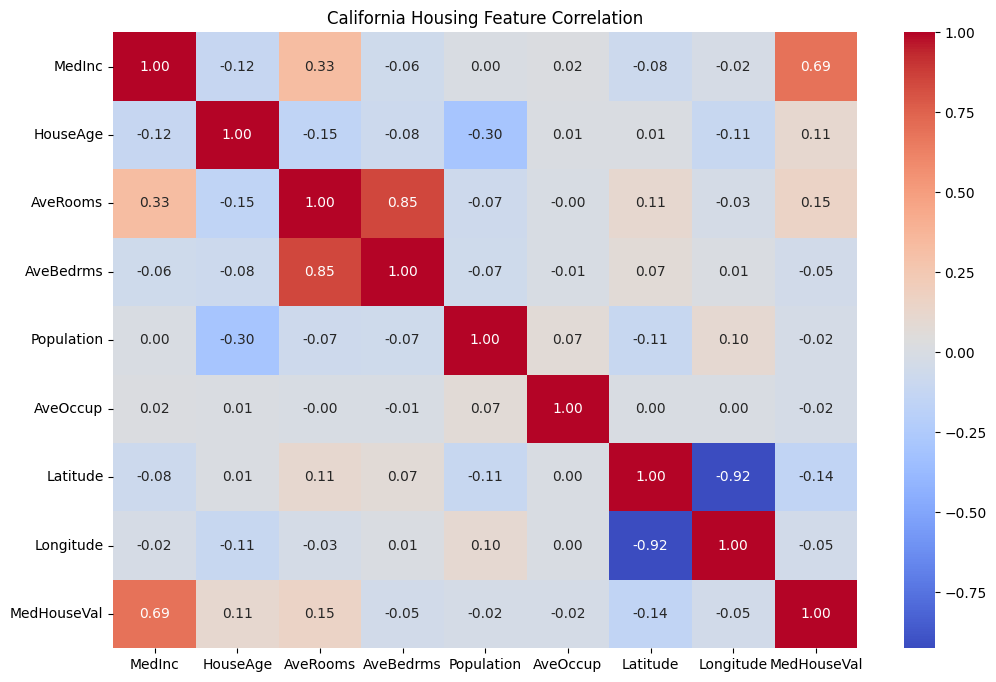

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("California Housing Feature Correlation")
plt.show()

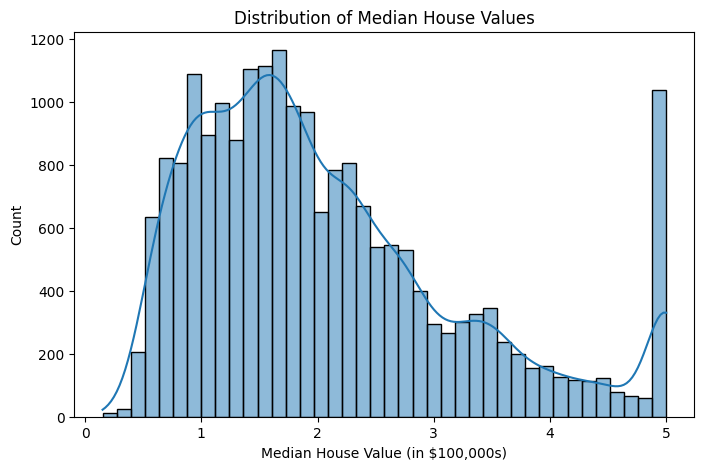

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(df["MedHouseVal"], bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in $100,000s)")
plt.show()

In [12]:
df_model = df.copy()

# Create interaction features
df_model["RoomsPerPerson"] = (
    df_model["AveRooms"] / (df_model["AveOccup"] + 1e-5)
)

df_model["BedroomsPerRoom"] = (
    df_model["AveBedrms"] / (df_model["AveRooms"] + 1e-5)
)

df_model["PopulationPerHousehold"] = (
    df_model["Population"] / (df_model["AveOccup"] + 1e-5)
)

df_model.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,RoomsPerPerson,BedroomsPerRoom,PopulationPerHousehold
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,2.732909,0.146591,125.999507
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,2.956671,0.155796,1137.994606
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,2.957651,0.129516,176.999368
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,2.283145,0.184458,218.999140
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,2.879633,0.172096,258.998813


In [13]:
X = df_model.drop("MedHouseVal", axis=1)
y = df_model["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 11)
Target shape: (20640,)


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


In [17]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (16512, 11)
Scaled testing shape: (4128, 11)


In [18]:
# OLS / Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)
ols_predictions = ols_model.predict(X_test_scaled)

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_predictions = ridge_model.predict(X_test_scaled)

# Lasso Regression
lasso_model = Lasso(alpha=0.01, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)
lasso_predictions = lasso_model.predict(X_test_scaled)

print("OLS, Ridge and Lasso models trained successfully!")

OLS, Ridge and Lasso models trained successfully!


In [19]:
results = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, ols_predictions)),
        np.sqrt(mean_squared_error(y_test, ridge_predictions)),
        np.sqrt(mean_squared_error(y_test, lasso_predictions))
    ],
    "MAE": [
        mean_absolute_error(y_test, ols_predictions),
        mean_absolute_error(y_test, ridge_predictions),
        mean_absolute_error(y_test, lasso_predictions)
    ],
    "R2 Score": [
        r2_score(y_test, ols_predictions),
        r2_score(y_test, ridge_predictions),
        r2_score(y_test, lasso_predictions)
    ]
})

results.round(4)

,Model,RMSE,MAE,R2 Score
0,OLS,0.6738,0.4874,0.6535
1,Ridge,0.6738,0.4874,0.6535
2,Lasso,0.6792,0.4903,0.6480


In [20]:
best_rmse_model = results.loc[results["RMSE"].idxmin(), "Model"]
best_r2_model = results.loc[results["R2 Score"].idxmax(), "Model"]

print("Best model by RMSE:", best_rmse_model)
print("Best model by R2 Score:", best_r2_model)

Best model by RMSE: OLS
Best model by R2 Score: OLS


In [21]:
ridge_grid = GridSearchCV(
    Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge CV RMSE:", -ridge_grid.best_score_)

Best Ridge alpha: {'alpha': 10}
Best Ridge CV RMSE: 0.6744393192944415


In [22]:
lasso_grid = GridSearchCV(
    Lasso(max_iter=20000),
    param_grid={"alpha": [0.0001, 0.001, 0.01, 0.1, 1]},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_)
print("Best Lasso CV RMSE:", -lasso_grid.best_score_)

Best Lasso alpha: {'alpha': 0.001}
Best Lasso CV RMSE: 0.6742713974089892


In [23]:
# Use best models found by GridSearchCV
ridge_best = ridge_grid.best_estimator_
lasso_best = lasso_grid.best_estimator_

# Predictions on untouched test data
ridge_best_predictions = ridge_best.predict(X_test_scaled)
lasso_best_predictions = lasso_best.predict(X_test_scaled)

# Final comparison
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

final_results = pd.DataFrame({
    "Model": ["OLS", "Tuned Ridge", "Tuned Lasso"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, ols_predictions)),
        np.sqrt(mean_squared_error(y_test, ridge_best_predictions)),
        np.sqrt(mean_squared_error(y_test, lasso_best_predictions))
    ],
    "MAE": [
        mean_absolute_error(y_test, ols_predictions),
        mean_absolute_error(y_test, ridge_best_predictions),
        mean_absolute_error(y_test, lasso_best_predictions)
    ],
    "R2 Score": [
        r2_score(y_test, ols_predictions),
        r2_score(y_test, ridge_best_predictions),
        r2_score(y_test, lasso_best_predictions)
    ]
})

final_results.round(4)

,Model,RMSE,MAE,R2 Score
0,OLS,0.6738,0.4874,0.6535
1,Tuned Ridge,0.6739,0.4874,0.6535
2,Tuned Lasso,0.6740,0.4874,0.6533


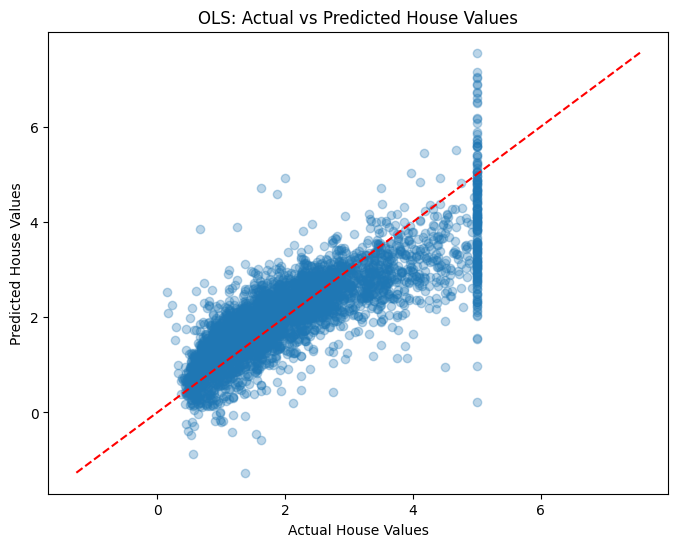

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, ols_predictions, alpha=0.3)

min_value = min(y_test.min(), ols_predictions.min())
max_value = max(y_test.max(), ols_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("OLS: Actual vs Predicted House Values")
plt.show()

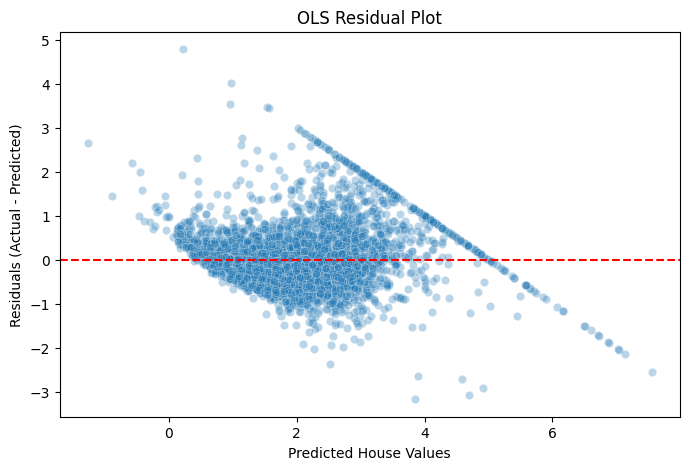

In [25]:
residuals = y_test - ols_predictions

plt.figure(figsize=(8, 5))

sns.scatterplot(x=ols_predictions, y=residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("OLS Residual Plot")
plt.show()

In [26]:
print("CALIFORNIA HOUSING PRICE PREDICTION")
print("=" * 45)

print("Dataset shape:", df.shape)
print("Features used:", X.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nBest Ridge alpha:", ridge_grid.best_params_["alpha"])
print("Best Lasso alpha:", lasso_grid.best_params_["alpha"])

print("\nFinal model comparison:")
display(final_results.round(4))

best_model = final_results.loc[
    final_results["RMSE"].idxmin(), "Model"
]

print("\nBest model by test RMSE:", best_model)

CALIFORNIA HOUSING PRICE PREDICTION
Dataset shape: (20640, 9)
Features used: 11
Training samples: 16512
Testing samples: 4128

Best Ridge alpha: 10
Best Lasso alpha: 0.001

Final model comparison:


,Model,RMSE,MAE,R2 Score
0,OLS,0.6738,0.4874,0.6535
1,Tuned Ridge,0.6739,0.4874,0.6535
2,Tuned Lasso,0.6740,0.4874,0.6533



Best model by test RMSE: OLS
